# Energy Transition & Electric Mobility in Portugal - Predictive Model

**Phase 4.** Target: `pct_renovavel` (domestic production) for the next day.
Starts with a naive climatology baseline, then Prophet, compared on the
same held-out test period.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df_ren = pd.read_csv(DATA_PROCESSED / "ren_daily_production.csv", parse_dates=["date"])
df_ren = df_ren.sort_values("date").reset_index(drop=True)

print(df_ren.shape)
df_ren[["date", "pct_renovavel"]].head()

(1826, 22)


,date,pct_renovavel
0,2021-10-07,44.4
1,2021-10-08,46.3
2,2021-10-09,62.6
3,2021-10-10,84.1
4,2021-10-11,69.2


## Train/test split

Time-ordered split, not random - the last 60 days are held out as the test
set, everything before that is training data. Shuffling would leak future
information into training, which doesn't reflect how this model would
actually be used in practice (predicting forward from today).

In [2]:
TEST_DAYS = 60

split_date = df_ren["date"].max() - pd.Timedelta(days=TEST_DAYS)

df_train = df_ren[df_ren["date"] <= split_date].copy()
df_test = df_ren[df_ren["date"] > split_date].copy()

print(
    f"Train: {len(df_train)} rows, {df_train['date'].min()} to {df_train['date'].max()}"
)
print(f"Test: {len(df_test)} rows, {df_test['date'].min()} to {df_test['date'].max()}")

Train: 1767 rows, 2021-10-07 00:00:00 to 2026-08-08 00:00:00
Test: 59 rows, 2026-08-09 00:00:00 to 2026-10-07 00:00:00


## Baseline: monthly climatology

Predicts each test day's `pct_renovavel` as the historical average for that
calendar month, computed from training data only (no leakage from the test
period). This is the bar to beat - if Prophet can't do meaningfully better
than this, the added complexity isn't worth it.

In [3]:
df_train["month"] = df_train["date"].dt.month
df_test["month"] = df_test["date"].dt.month

monthly_climatology = df_train.groupby("month")["pct_renovavel"].mean()

df_test["baseline_pred"] = df_test["month"].map(monthly_climatology)

baseline_mae = (df_test["pct_renovavel"] - df_test["baseline_pred"]).abs().mean()
print(f"Baseline MAE: {baseline_mae:.2f} percentage points")

Baseline MAE: 10.52 percentage points


## Prophet model

Fitting Prophet on the training data only, then predicting the same 60
test days as the baseline, for a fair comparison.

Heads-up: Prophet can be fussy to install on Windows (it depends on
cmdstanpy, which sometimes needs extra setup). If the install below fails,
paste the error and we'll sort it out rather than guessing in advance.

In [4]:
from prophet import Prophet

# Prophet requires exactly two columns, named "ds" (date) and "y" (value)
df_prophet_train = df_train[["date", "pct_renovavel"]].rename(
    columns={"date": "ds", "pct_renovavel": "y"}
)

model = Prophet(
    yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False
)
model.fit(df_prophet_train)

C:\Users\joaof\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
23:34:58 - cmdstanpy - INFO - Chain [1] start processing
23:34:59 - cmdstanpy - INFO - Chain [1] done processing


## Generate predictions and compare to baseline

Prophet needs a "future" dataframe listing the dates to predict - built
from the test set's own dates, so the comparison lines up exactly with
the baseline.

In [5]:
future = df_test[["date"]].rename(columns={"date": "ds"})
forecast = model.predict(future)

# yhat is Prophet's point prediction; yhat_lower/yhat_upper are the
# uncertainty interval, useful later for the dashboard
df_test["prophet_pred"] = forecast["yhat"].values

prophet_mae = (df_test["pct_renovavel"] - df_test["prophet_pred"]).abs().mean()

print(f"Baseline MAE: {baseline_mae:.2f} percentage points")
print(f"Prophet MAE:  {prophet_mae:.2f} percentage points")

Baseline MAE: 10.52 percentage points
Prophet MAE:  6.80 percentage points


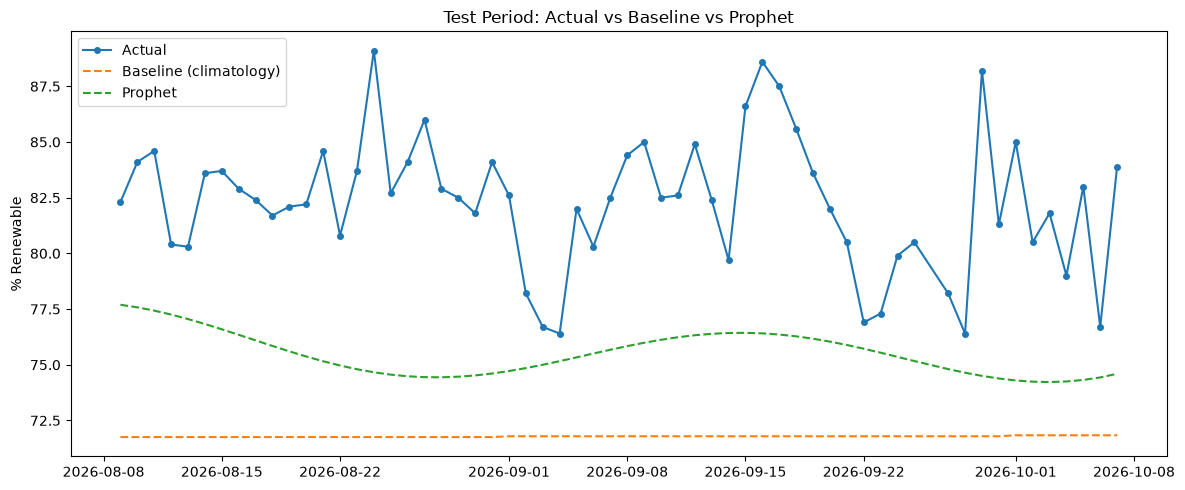

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    df_test["date"], df_test["pct_renovavel"], label="Actual", marker="o", markersize=4
)
ax.plot(
    df_test["date"],
    df_test["baseline_pred"],
    label="Baseline (climatology)",
    linestyle="--",
)
ax.plot(df_test["date"], df_test["prophet_pred"], label="Prophet", linestyle="--")
ax.set_ylabel("% Renewable")
ax.set_title("Test Period: Actual vs Baseline vs Prophet")
ax.legend()
plt.tight_layout()
plt.show()

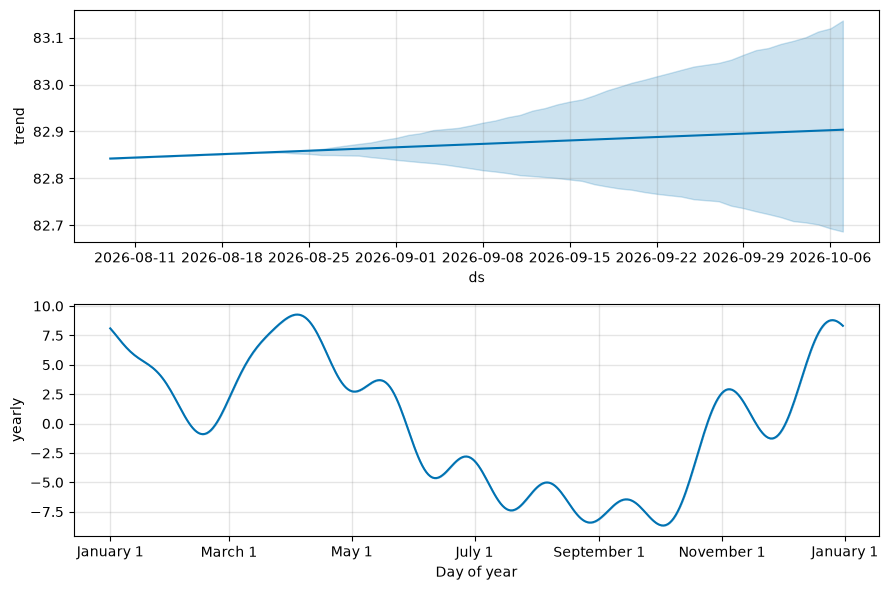

In [7]:
model.plot_components(forecast)
plt.show()

In [8]:
model_smooth = Prophet(
    yearly_seasonality=4, weekly_seasonality=False, daily_seasonality=False
)
model_smooth.fit(df_prophet_train)

forecast_smooth = model_smooth.predict(future)
df_test["prophet_smooth_pred"] = forecast_smooth["yhat"].values

prophet_smooth_mae = (
    (df_test["pct_renovavel"] - df_test["prophet_smooth_pred"]).abs().mean()
)

print(f"Baseline MAE:        {baseline_mae:.2f}")
print(f"Prophet (default):   {prophet_mae:.2f}")
print(f"Prophet (smoothed):  {prophet_smooth_mae:.2f}")

23:34:59 - cmdstanpy - INFO - Chain [1] start processing
23:34:59 - cmdstanpy - INFO - Chain [1] done processing


Baseline MAE:        10.52
Prophet (default):   6.80
Prophet (smoothed):  6.87


In [9]:
from sklearn.linear_model import LinearRegression

df_reg = df_ren.copy()
df_reg["day_of_year"] = df_reg["date"].dt.dayofyear
df_reg["doy_sin"] = np.sin(2 * np.pi * df_reg["day_of_year"] / 365)
df_reg["doy_cos"] = np.cos(2 * np.pi * df_reg["day_of_year"] / 365)
df_reg["lag_1"] = df_reg["pct_renovavel"].shift(1)
df_reg["rolling_7"] = df_reg["pct_renovavel"].shift(1).rolling(7).mean()

df_reg = df_reg.dropna(subset=["lag_1", "rolling_7"])

features = ["doy_sin", "doy_cos", "lag_1", "rolling_7"]

df_reg_train = df_reg[df_reg["date"] <= split_date]
df_reg_test = df_reg[df_reg["date"] > split_date]

reg_model = LinearRegression()
reg_model.fit(df_reg_train[features], df_reg_train["pct_renovavel"])

reg_pred = reg_model.predict(df_reg_test[features])
reg_mae = (df_reg_test["pct_renovavel"] - reg_pred).abs().mean()

print(f"Baseline MAE:        {baseline_mae:.2f}")
print(f"Prophet (default):   {prophet_mae:.2f}")
print(f"Regression (lag):    {reg_mae:.2f}")

Baseline MAE:        10.52
Prophet (default):   6.80
Regression (lag):    2.41


In [10]:
for feature, coef in zip(features, reg_model.coef_):
    print(f"{feature:12s} {coef:+.3f}")

doy_sin      +0.261
doy_cos      +0.341
lag_1        +0.694
rolling_7    +0.233


## Final comparison: all three approaches

Visual summary closing Phase 4 - actual values against the baseline,
Prophet, and the lag regression, with each model's MAE in the legend.


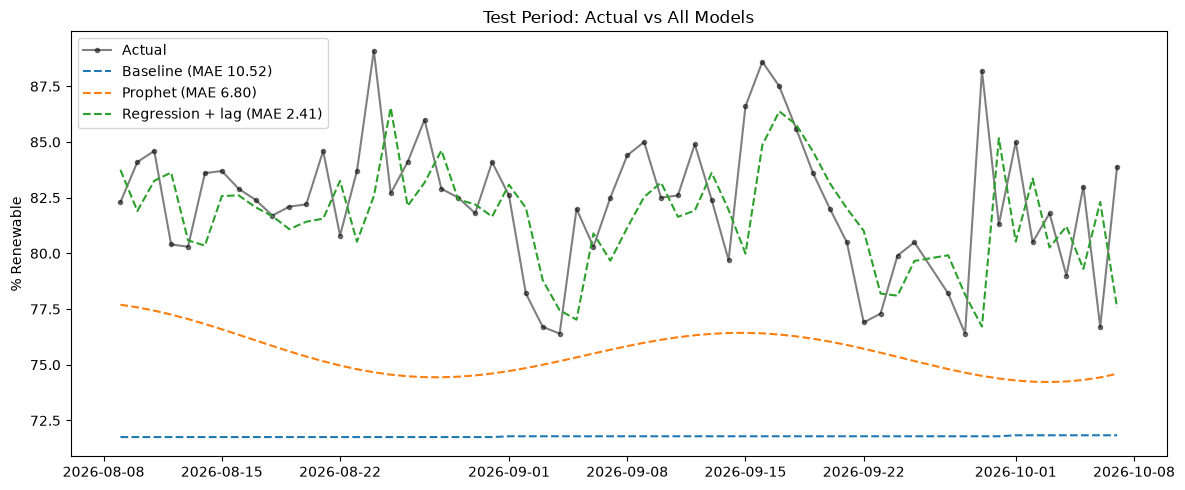

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df_test["date"],
    df_test["pct_renovavel"],
    label="Actual",
    color="black",
    marker="o",
    alpha=0.5,
    markersize=3,
)
ax.plot(
    df_test["date"],
    df_test["baseline_pred"],
    label=f"Baseline (MAE {baseline_mae:.2f})",
    linestyle="--",
)
ax.plot(
    df_test["date"],
    df_test["prophet_pred"],
    label=f"Prophet (MAE {prophet_mae:.2f})",
    linestyle="--",
)
ax.plot(
    df_reg_test["date"],
    reg_pred,
    label=f"Regression + lag (MAE {reg_mae:.2f})",
    linestyle="--",
)

ax.set_ylabel("% Renewable")
ax.set_title("Test Period: Actual vs All Models")
ax.legend()
plt.tight_layout()
plt.show()